# Lab 2 - HDBSCAN
## JS08 - Hierarchical Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097



In [4]:
%pip install hdbscan

   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.9 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.9 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/1.9 MB 722.1 kB/s eta 0:00:02
   ---------------- ----------------------- 0.8/1.9 MB 824.8 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/1.9 MB 882.7 kB/s eta 0:00:02
   --------------------- ------------------ 1.0/1.9 MB 882.7 kB/s eta 0:00:02
   -------------------------- ------------- 1.3/1.9 MB 789.4 kB/s eta 0:00:01
   -------------------------- ------------- 1.3/1.9 MB 789.4 kB/s eta 0:00:01
   -------------------------------- ------- 1.6/1.9 MB 790.7 kB/s eta 0:00:01
   -------------------------------- ------- 1.6/1.9 MB 790.7 kB/s eta 0:00:01
   -------------------------------- ------- 1.6/1.9 MB 790.7 kB/s eta 0:00:01
   -------------------


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


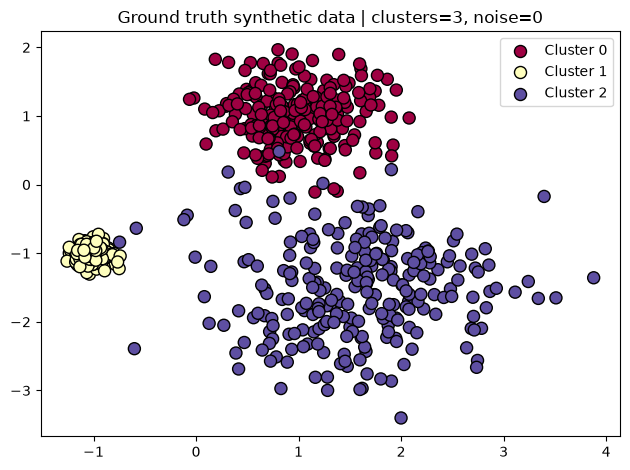

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import hdbscan
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs

def plot_clusters(X, labels, probabilities=None, title=''):
    probabilities = np.ones(len(X)) if probabilities is None else probabilities
    unique = sorted(set(labels))
    colors = plt.cm.Spectral(np.linspace(0, 1, max(len(unique), 1)))
    for color, cluster in zip(colors, unique):
        mask = labels == cluster
        point_color = 'black' if cluster == -1 else color
        marker = 'x' if cluster == -1 else 'o'
        sizes = 18 if cluster == -1 else 20 + 55 * probabilities[mask]
        plt.scatter(X[mask, 0], X[mask, 1], c=[point_color], s=sizes, marker=marker,
                    edgecolors='black' if cluster != -1 else None, label=f'Cluster {cluster}')
    n_clusters = len(set(labels)) - int(-1 in labels)
    plt.title(f'{title} | clusters={n_clusters}, noise={(labels == -1).sum()}')
    plt.legend(loc='best')
    plt.tight_layout()

centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(n_samples=750, centers=centers,
                            cluster_std=[0.4, 0.1, 0.75], random_state=0)
plot_clusters(X, labels_true, title='Ground truth synthetic data')
plt.show()

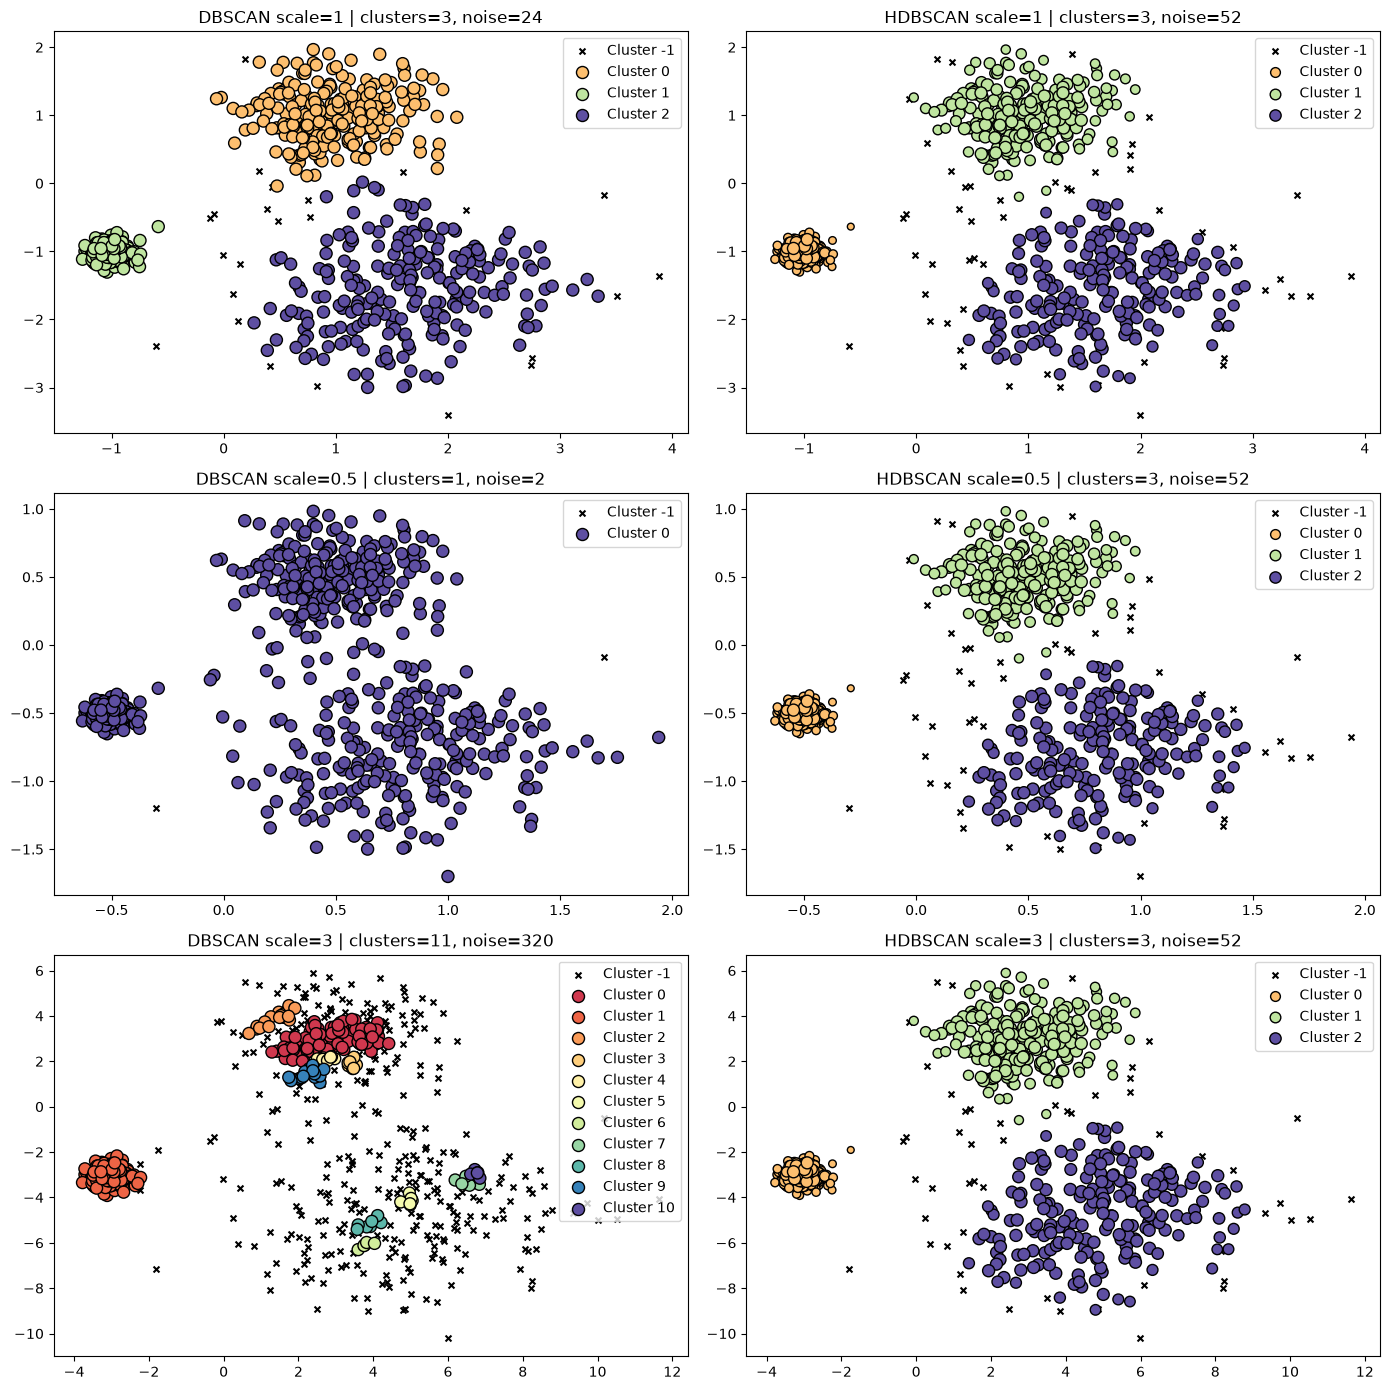

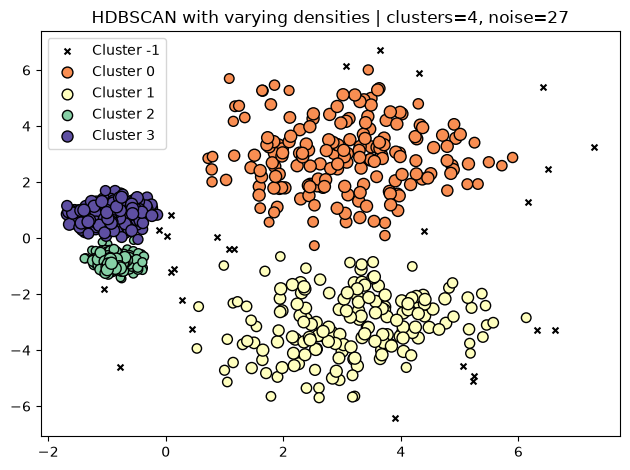

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for row, scale in enumerate([1, 0.5, 3]):
    db = DBSCAN(eps=0.3).fit(X * scale)
    plt.sca(axes[row, 0])
    plot_clusters(X * scale, db.labels_, title=f'DBSCAN scale={scale}')
    hdb = hdbscan.HDBSCAN().fit(X * scale)
    plt.sca(axes[row, 1])
    plot_clusters(X * scale, hdb.labels_, hdb.probabilities_, title=f'HDBSCAN scale={scale}')
plt.tight_layout()
plt.show()

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(n_samples=750, centers=centers,
                            cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0)
hdb = hdbscan.HDBSCAN().fit(X)
plot_clusters(X, hdb.labels_, hdb.probabilities_, title='HDBSCAN with varying densities')
plt.show()

### Observation
DBSCAN uses one global `eps`, so changing the scale can change its result substantially. HDBSCAN builds a hierarchy and is less dependent on one global radius, while explicitly marking low-density observations as noise (`-1`).